Step 2: Data Cleaning & Preprocessing

In [1]:
import pandas as pd
import numpy as np

In [2]:
df = pd.read_csv("Budget_vs_Actual_Data.csv")

Dataset Overview

In [3]:
df.shape

(10010, 8)

In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10010 entries, 0 to 10009
Data columns (total 8 columns):
 #   Column          Non-Null Count  Dtype 
---  ------          --------------  ----- 
 0   Date            10010 non-null  object
 1   Department      10009 non-null  object
 2   Category        10009 non-null  object
 3   Region          10007 non-null  object
 4   Budget Amount   10010 non-null  int64 
 5   Actual Amount   10010 non-null  int64 
 6   Payment Method  10010 non-null  object
 7   Transaction ID  10007 non-null  object
dtypes: int64(2), object(6)
memory usage: 625.8+ KB


In [5]:
df.head()

,Date,Department,Category,Region,Budget Amount,Actual Amount,Payment Method,Transaction ID
0,2023/05/11 00:00:00,Sales,Travel,North,126096,43048,Card,TXN100000
1,2023/11/11 00:00:00,Marketing,Salaries,East,19702,87896,Bank Transfer,TXN100001
2,2021/05/02 00:00:00,IT,Training,Central,108523,103632,Card,TXN100002
3,2022/04/12 00:00:00,Marketing,Salaries,North,114711,105574,Cash,TXN100003
4,2021/11/27 00:00:00,Sales,Utilities,Central,121895,64314,UPI,TXN100004


Check Missing Values

In [6]:
df.isnull().sum()

Date              0
Department        1
Category          1
Region            3
Budget Amount     0
Actual Amount     0
Payment Method    0
Transaction ID    3
dtype: int64

In [7]:
(df.isnull().sum()/len(df))*100

Date              0.00000
Department        0.00999
Category          0.00999
Region            0.02997
Budget Amount     0.00000
Actual Amount     0.00000
Payment Method    0.00000
Transaction ID    0.02997
dtype: float64

Handle Missing Values

In [8]:
num_cols = ['Budget Amount','Actual Amount']

for col in num_cols:
    df[col].fillna(df[col].median(), inplace=True)

/var/folders/yz/h77tp7jx2yg0phtmwpq6b1580000gn/T/ipykernel_2963/2485739626.py:4: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df[col].fillna(df[col].median(), inplace=True)
/var/folders/yz/h77tp7jx2yg0phtmwpq6b1580000gn/T/ipykernel_2963/2485739626.py:4: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always b

In [9]:
cat_cols = ['Department','Category']

for col in cat_cols:
    df[col].fillna(df[col].mode()[0], inplace=True)

/var/folders/yz/h77tp7jx2yg0phtmwpq6b1580000gn/T/ipykernel_2963/1278553139.py:4: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df[col].fillna(df[col].mode()[0], inplace=True)


Check Duplicate Records

In [10]:
df.duplicated().sum()

np.int64(10)

In [11]:
df.drop_duplicates(inplace=True)

Fix Data Types

In [12]:
df.dtypes

Date              object
Department        object
Category          object
Region            object
Budget Amount      int64
Actual Amount      int64
Payment Method    object
Transaction ID    object
dtype: object

In [13]:
df['Date'] = pd.to_datetime(df['Date'])

Convert to Proper Case

In [14]:
df['Department'] = df['Department'].str.title()

df['Category'] = df['Category'].str.title()

In [15]:
df['Department'] = df['Department'].str.strip()

df['Category'] = df['Category'].str.strip()

Check Negative Values

In [20]:
df[df['Budget Amount'] < 0]

,Date,Department,Category,Region,Budget Amount,Actual Amount,Payment Method,Transaction ID


In [19]:
df[df['Actual Amount'] < 0]

,Date,Department,Category,Region,Budget Amount,Actual Amount,Payment Method,Transaction ID


Remove Invalid Records

In [21]:
df = df[
    (df['Budget Amount'] >= 0) &
    (df['Actual Amount'] >= 0)
]

Detect Outliers

Budget Amount

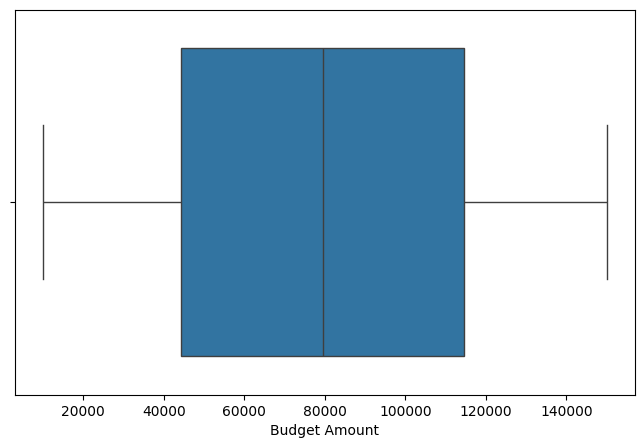

In [22]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(8,5))

sns.boxplot(
    x=df['Budget Amount']
)

plt.show()

Actual Amount

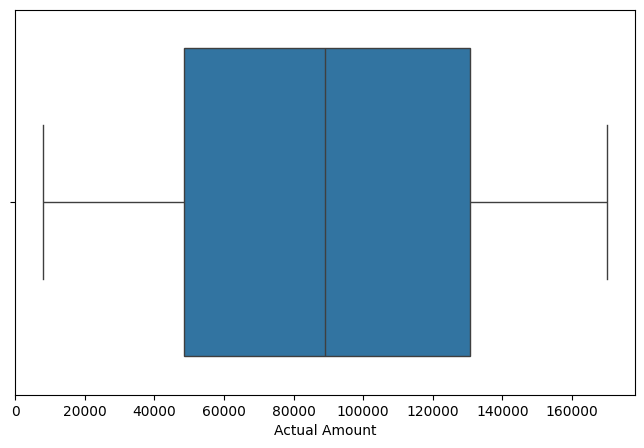

In [23]:
plt.figure(figsize=(8,5))

sns.boxplot(
    x=df['Actual Amount']
)

plt.show()

Remove Outliers (IQR Method)

Budget Amount

In [24]:
Q1 = df['Budget Amount'].quantile(0.25)
Q3 = df['Budget Amount'].quantile(0.75)

IQR = Q3 - Q1

lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR

df = df[
    (df['Budget Amount'] >= lower) &
    (df['Budget Amount'] <= upper)
]

Actual Amount

In [25]:
Q1 = df['Actual Amount'].quantile(0.25)
Q3 = df['Actual Amount'].quantile(0.75)

IQR = Q3 - Q1

lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR

df = df[
    (df['Actual Amount'] >= lower) &
    (df['Actual Amount'] <= upper)
]

Create Clean Features

Variance

In [26]:
df['Variance'] = (
    df['Actual Amount']
    - df['Budget Amount']
)

Variance %

In [27]:
df['Variance %'] = (
    df['Variance']
    /
    df['Budget Amount']
) * 100

Budget Status

In [28]:
df['Status'] = np.where(
    df['Actual Amount']
    >
    df['Budget Amount'],
    'Over Budget',
    'Within Budget'
)

Validate Data

In [29]:
df.describe()

,Date,Budget Amount,Actual Amount,Variance,Variance %
count,10000,10000.000000,10000.000000,10000.000000,10000.000000
mean,2022-07-08 15:15:07.200000,79546.925600,89026.702900,9479.777300,73.414910
min,2021-01-01 00:00:00,10005.000000,8002.000000,-138773.000000,-94.204806
25%,2021-10-08 00:00:00,44383.000000,48558.750000,-35006.000000,-38.795286
50%,2022-07-12 00:00:00,79558.000000,89169.500000,9518.000000,11.724093
75%,2023-04-09 00:00:00,114597.500000,130593.000000,54225.250000,101.613561
max,2023-12-31 00:00:00,149992.000000,169973.000000,158737.000000,1500.089829
std,NaN,40499.314105,46952.695095,61660.074091,194.436871


In [30]:
df.isnull().sum()

Date              0
Department        0
Category          0
Region            3
Budget Amount     0
Actual Amount     0
Payment Method    0
Transaction ID    3
Variance          0
Variance %        0
Status            0
dtype: int64

In [31]:
df.duplicated().sum()

np.int64(0)

Save Cleaned Dataset

In [33]:
df.to_csv(
    "cleaned_budget_data.csv",
    index=False
)